# 7. Texto: cobertura, duplicados y disponibilidad

Se audita la recuperación por mes y fuente, sin clasificar temas, sentimiento, anticipación ni relevancia. La comparación de cobertura usa sólo metadatos de procedencia. El análisis de longitud y coincidencias de contenido se limita a entrenamiento.

Por decisión del autor se incluyen versiones no acreditadas en el conjunto ampliado. `available_at_assumed` nunca se confunde con `available_at_verified`. Se usa la hora declarada con zona; si sólo se conoce el día, se supone ingreso desde las 00:00 del día siguiente en Colombia. Esto no acredita que una versión recuperada en 2026 fuera idéntica a la original. Los títulos sin fecha permanecen en el inventario y no se asignan cronológicamente.

Se examinan repeticiones exactas, variaciones ortográficas y cambios parecidos dentro de una misma URL. No se entrenan agrupamientos semánticos sobre el corpus completo. Un título repetido en boletines diarios puede ser legítimo: la repetición no equivale automáticamente a duplicado de artículo ni a fuga de un pronóstico.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/manifest.json').exists())
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
from IPython.display import display,Markdown
from colombia_energy import eda
pd.set_option('display.max_rows',35)
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')


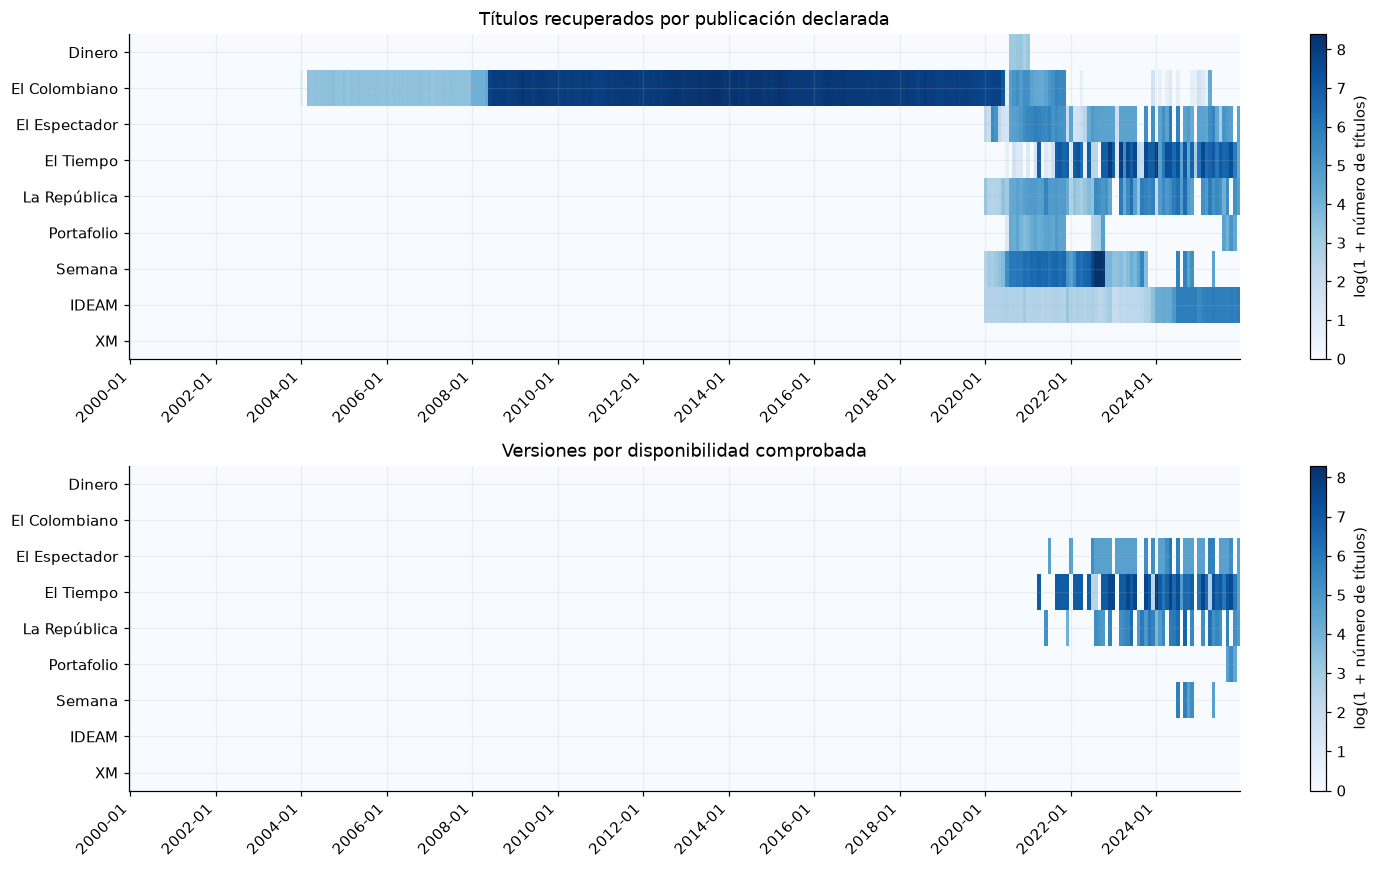

caracteres                    palabras_espacio                \
                   count median   mean  max            count median   mean   
source                                                                       
El Colombiano     380541     47 48.125  950           380541      8 8.0122   

                    
               max  
source              
El Colombiano  166

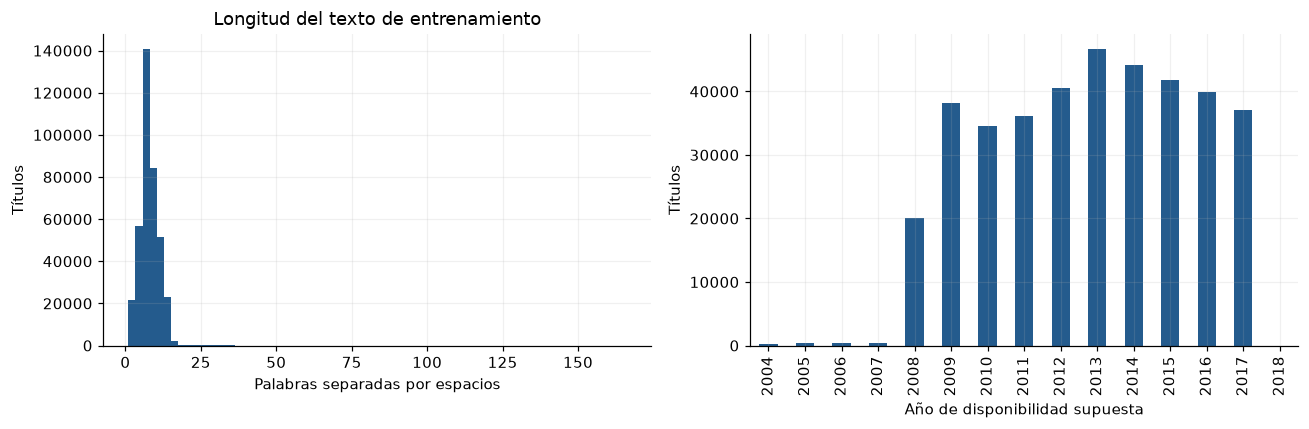

,n
textos fechados elegibles en train ampliado,380541
id repetidos,0
titulares normalizados repetidos,7925
coincidencias ignorando tildes/puntuación/caja,8149
URL canónicas repetidas,0
textos de hasta 3 palabras,21621


,url_sha256,similitud_caracteres


Las coincidencias de título no se eliminan automáticamente: un boletín diario o una caricatura puede conservar el mismo título en fechas distintas. El criterio de casi duplicado anterior es ortográfico y limitado a una misma URL; no certifica ausencia de paráfrasis o sindicación entre URLs. No se calculan temas, sentimiento ni relevancia.

,titles_all_period,titles_declared_2020_2025,titles_publication_date_unknown,versions_verified_available_by_end_2025,months_2020_2025_with_declared_titles,months_2020_2025_with_verified_availability
Dinero,129,129,0,0,6,0
El Colombiano,461461,15869,0,0,35,0
El Espectador,8550,8550,0,4697,64,33
El Tiempo,49350,49350,0,48323,61,46
La República,10381,10381,0,8162,67,31
Portafolio,1815,1815,0,391,25,3
Semana,29386,29386,0,999,51,5
IDEAM,7223,7223,0,0,72,0
XM,406,0,406,0,0,0


### Implicaciones del análisis

- **Preprocesamiento:** Conservar máscaras de recuperación/fuente y fechas supuestas/comprobadas. No rellenar texto ausente con un resumen generado.
- **Arquitectura:** Encoder y mecanismo de utilidad entrenados con train; permitir que el modelo ignore texto corto/repetitivo. Agrupamiento, si se usa, se aprende dentro del pipeline.
- **Validación:** Auditar cambios de fuente y cantidad de texto; comparar con/sin NLP en los mismos orígenes y con textos placebo en el benchmark futuro.
- **Riesgos:** La cobertura cambia mucho entre épocas y puede actuar como atajo. El conjunto ampliado autorizado contiene versiones retrospectivas no acreditadas; no es una demostración libre de fuga. Los anexos ZIP y nombres de informes aportan una señal semántica limitada.

In [2]:
eda.text_analysis()